# SSNP Optical Diffraction Tomography

**Goal:** Reconstruct the 3D refractive index (RI) distribution of a biological sample from multi-angle complex field measurements using the Split-Step Non-Paraxial (SSNP) wave propagation model.

**Key distinction from IDT:** Optical Diffraction Tomography (ODT) retains the full complex field $E$ at the detector — both amplitude $|E|$ and phase $\angle E$ — rather than discarding phase by recording only intensity $|E|^2$. This extra information makes the inverse problem better constrained.

**Notebook structure:**
1. Problem background and forward model
2. Data: complex field measurements and ground truth
3. Reconstruction results (precomputed)
4. Metrics and convergence
5. Commented-out code to reproduce from scratch

In [1]:
import os, sys

# Navigate to the task root so data/ and src/ resolve correctly
task_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
os.chdir(task_root)
if task_root not in sys.path:
    sys.path.insert(0, task_root)

import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
%matplotlib inline

print("Working directory:", os.getcwd())

Working directory: /projects/bgkc/schen47/imaging-101/tasks/ssnp_odt


## 1. Problem Background

### Forward model: SSNP

The sample is described by an RI contrast volume $\Delta n(x,y,z) = n(x,y,z) - n_0$, where $n_0 = 1.0$ is the background RI.

For each illumination angle $l$, an incident tilted plane wave $\Phi_0^l = (\varphi_0^l,\, \partial_z \varphi_0^l)$ propagates through the volume. The SSNP model alternates two operators per axial slice $z_k$:

**P operator** (free-space diffraction, Fourier domain):
$$
\begin{pmatrix} \hat{a}^\text{new} \\ \hat{a}_d^\text{new} \end{pmatrix}
=
\begin{pmatrix} \cos(k_z \Delta z) & \sin(k_z \Delta z)/k_z \\ -k_z\sin(k_z \Delta z) & \cos(k_z \Delta z) \end{pmatrix}
\begin{pmatrix} \hat{a} \\ \hat{a}_d \end{pmatrix}
$$
where $k_z = 2\pi \cdot r_z \cdot \sqrt{1 - f_x^2 - f_y^2}$ is the axial wave vector and $r_z = \Delta z_\text{phys} \cdot n_0 / \lambda$ is the normalised axial resolution. Evanescent components ($|f| > 1$) are exponentially damped.

**Q operator** (RI scattering, real space):
$$
u_d \leftarrow u_d - k_0^2 \bigl(2 n_0 \Delta n + \Delta n^2\bigr)\, \Delta z_\text{phys} \cdot u
$$
where the physical thickness factor $\Delta z_\text{phys} = (2\pi r_z / n_0)^2$.

After traversing all $N_z$ slices, the exit field is back-propagated to the focal plane, the forward-propagating component is extracted, and a binary pupil filter limits spatial frequencies to $\text{NA}/\lambda$:
$$
E^l = \mathcal{P}_\text{NA} \cdot F \cdot P_{-N_z/2} \cdot [P \cdot Q]^{N_z} \cdot \Phi_0^l
$$

### Inverse problem

Given $L = 8$ complex field measurements $\{E^l\}_{l=0}^{7}$, recover $\Delta n$ by minimising:
$$
\mathcal{L}(\Delta n) = \sum_{l=0}^{L-1} \frac{1}{N_\text{pix}} \sum_{x,y} |E^l_\text{pred}(\Delta n;\, x,y) - E^l_\text{meas}(x,y)|^2
$$
subject to $\Delta n \geq 0$ (non-negativity for biological samples in aqueous medium).

Gradients $\partial \mathcal{L}/\partial \Delta n$ are computed via PyTorch autograd through the complex SSNP operators.

## 2. Data

In [2]:
# Load metadata
with open("data/meta_data.json") as f:
    meta = json.load(f)

print("Imaging parameters:")
for k, v in meta.items():
    if k != "description":
        print(f"  {k:25s}: {v}")

Imaging parameters:
  volume_shape             : [308, 256, 256]
  res_um                   : [0.1, 0.1, 0.1]
  wavelength_um            : 0.5
  n0                       : 1.0
  NA                       : 0.65
  n_angles                 : 8
  ri_contrast_scale        : 0.01
  tiff_scale               : 1.0


In [3]:
# Load complex measurements and ground truth
raw = np.load("data/raw_data.npz")
gt_data = np.load("data/ground_truth.npz")

measurements = raw["measurements"][0].astype(np.complex128)   # (8, 256, 256)
phantom_dn   = gt_data["delta_n"][0].astype(np.float64)       # (308, 256, 256)

n_angles, ny, nx = measurements.shape
nz = phantom_dn.shape[0]

amp = np.abs(measurements)
print(f"Measurements : shape {measurements.shape}  dtype {measurements.dtype}")
print(f"  amplitude  : [{amp.min():.4f}, {amp.max():.4f}]")
print(f"  phase      : [{np.angle(measurements).min():.4f}, {np.angle(measurements).max():.4f}] rad")
print(f"Ground truth : shape {phantom_dn.shape}  Δn [{phantom_dn.min():.6f}, {phantom_dn.max():.6f}]")

Measurements : shape (8, 256, 256)  dtype complex128
  amplitude  : [0.5645, 1.3924]
  phase      : [-3.1416, 3.1416] rad
Ground truth : shape (308, 256, 256)  Δn [0.000000, 0.010000]


### Illumination geometry

Eight plane waves illuminate the sample from directions on an annular ring at NA = 0.65. Angle $l$ has transverse wave-vector components:
$$k_x^l = \frac{\text{NA}}{n_0} \cos\!\left(\frac{2\pi l}{L}\right), \qquad k_y^l = \frac{\text{NA}}{n_0} \sin\!\left(\frac{2\pi l}{L}\right)$$

/tmp/ipykernel_1605067/4007242354.py:26: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


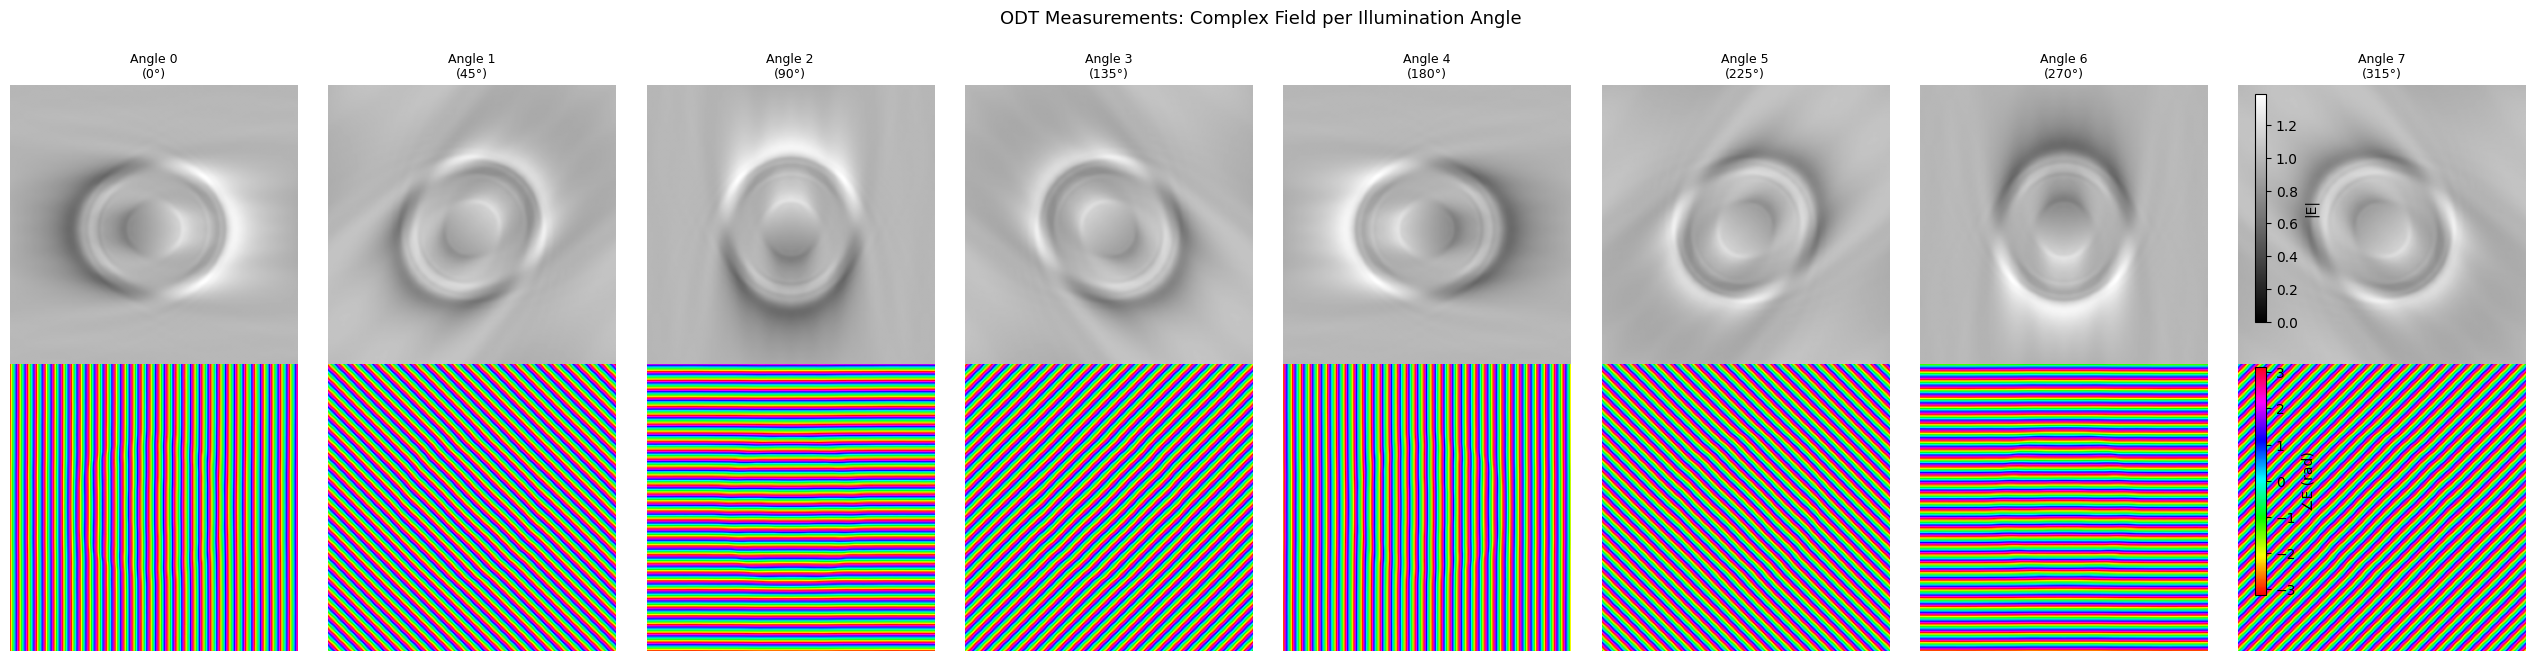

In [4]:
# Visualise complex measurements: amplitude (top row) and phase (bottom row)
fig, axes = plt.subplots(2, n_angles, figsize=(3.2 * n_angles, 6.5))

amp_all   = np.abs(measurements)
phase_all = np.angle(measurements)
vmax_amp  = amp_all.max()

for i in range(n_angles):
    theta = 360 * i / n_angles

    im0 = axes[0, i].imshow(amp_all[i], cmap="gray", origin="lower",
                             vmin=0, vmax=vmax_amp)
    axes[0, i].set_title(f"Angle {i}\n({theta:.0f}°)", fontsize=9)
    axes[0, i].axis("off")

    im1 = axes[1, i].imshow(phase_all[i], cmap="hsv", origin="lower",
                             vmin=-np.pi, vmax=np.pi)
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Amplitude |E|", fontsize=10)
axes[1, 0].set_ylabel("Phase ∠E (rad)", fontsize=10)

fig.colorbar(im0, ax=axes[0, :].tolist(), fraction=0.015, pad=0.02, label="|E|")
fig.colorbar(im1, ax=axes[1, :].tolist(), fraction=0.015, pad=0.02, label="∠E (rad)")
fig.suptitle("ODT Measurements: Complex Field per Illumination Angle", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

### Ground truth phantom

The phantom is a 308-slice biological sample (from the [bu-cisl/SSNP-IDT](https://github.com/bu-cisl/SSNP-IDT) repository) with RI contrast $\Delta n \in [0,\, 0.01]$, voxel size 100 nm isotropic.

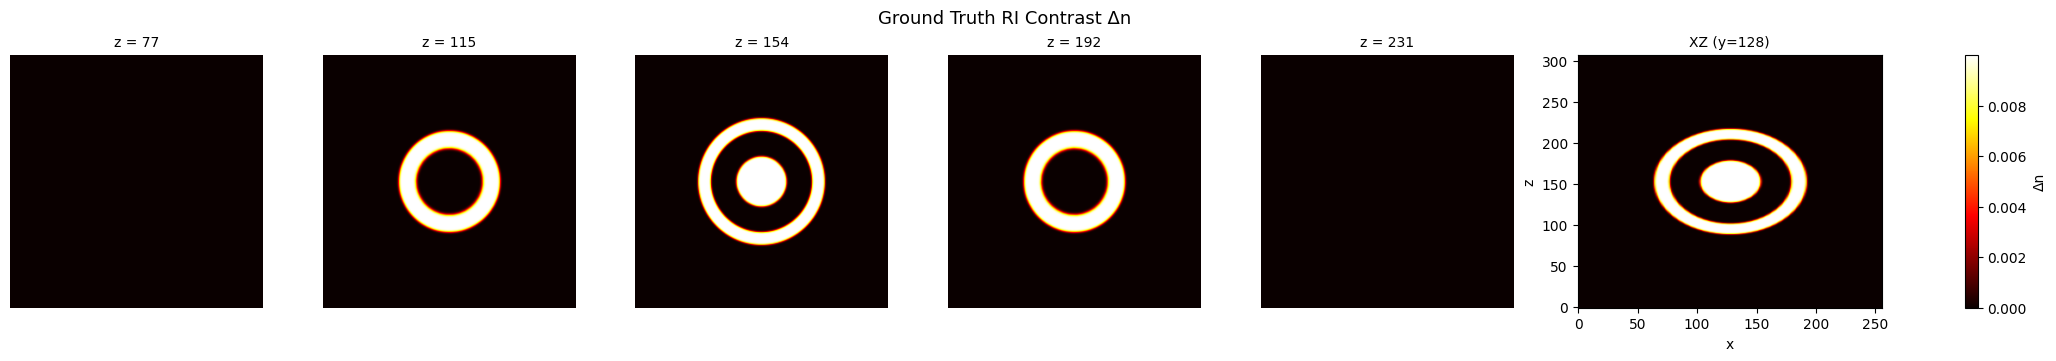

In [5]:
# Show 5 XY slices and one XZ cross-section of the ground truth
z_indices = np.linspace(nz // 4, 3 * nz // 4, 5, dtype=int)
vmax_dn = np.percentile(phantom_dn, 99.5)

fig, axes = plt.subplots(1, 6, figsize=(21, 3.5), constrained_layout=True)

for ax, zi in zip(axes[:5], z_indices):
    im = ax.imshow(phantom_dn[zi], cmap="hot", origin="lower", vmin=0, vmax=vmax_dn)
    ax.set_title(f"z = {zi}", fontsize=10)
    ax.axis("off")

# XZ cross-section
xz = phantom_dn[:, ny // 2, :]
axes[5].imshow(xz, cmap="hot", origin="lower", vmin=0, vmax=vmax_dn, aspect="auto")
axes[5].set_title(f"XZ (y={ny//2})", fontsize=10)
axes[5].set_xlabel("x"); axes[5].set_ylabel("z")

fig.colorbar(im, ax=axes.tolist(), fraction=0.01, pad=0.04, label="Δn")
fig.suptitle("Ground Truth RI Contrast Δn", fontsize=13)
plt.show()

## 3. Reconstruction Results

Results are loaded from `evaluation/reference_outputs/` (precomputed on an NVIDIA GH200 120GB GPU). To reproduce from scratch, see the commented-out code in **Section 5**.

**Solver:** Gradient descent, 100 iterations, learning rate $\eta = 5.0$, no TV regularisation, non-negativity projection after each step.

In [6]:
# Load precomputed reconstruction and loss history
dn_recon     = np.load("evaluation/reference_outputs/reconstruction.npy")
loss_history = np.load("evaluation/reference_outputs/loss_history.npy")

print(f"Reconstruction : shape {dn_recon.shape}  Δn [{dn_recon.min():.6f}, {dn_recon.max():.6f}]")
print(f"Loss history   : {len(loss_history)} iterations,  {loss_history[0]:.4f} → {loss_history[-1]:.6f}")

Reconstruction : shape (308, 256, 256)  Δn [0.000000, 0.011959]
Loss history   : 100 iterations,  0.6138 → 0.001413


### Convergence

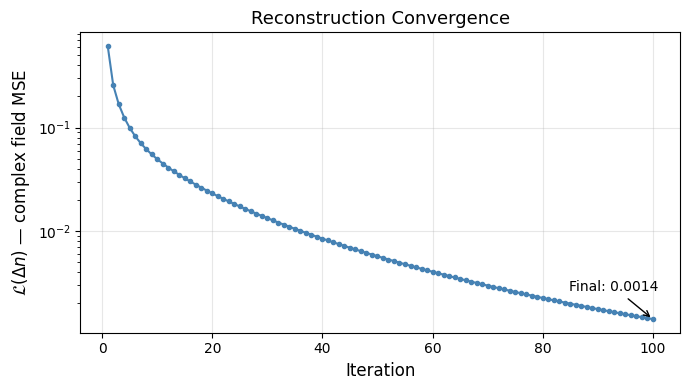

Loss reduction: 434×


In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(range(1, len(loss_history) + 1), loss_history, "o-",
            color="steelblue", ms=3, lw=1.5)
ax.set_xlabel("Iteration", fontsize=12)
ax.set_ylabel(r"$\mathcal{L}(\Delta n)$ — complex field MSE", fontsize=12)
ax.set_title("Reconstruction Convergence", fontsize=13)
ax.grid(True, alpha=0.3)
ax.annotate(f"Final: {loss_history[-1]:.4f}",
            xy=(len(loss_history), loss_history[-1]),
            xytext=(-60, 20), textcoords="offset points",
            arrowprops=dict(arrowstyle="->"), fontsize=10)
plt.tight_layout()
plt.show()
print(f"Loss reduction: {loss_history[0]/loss_history[-1]:.0f}×")

### Ground truth vs reconstruction

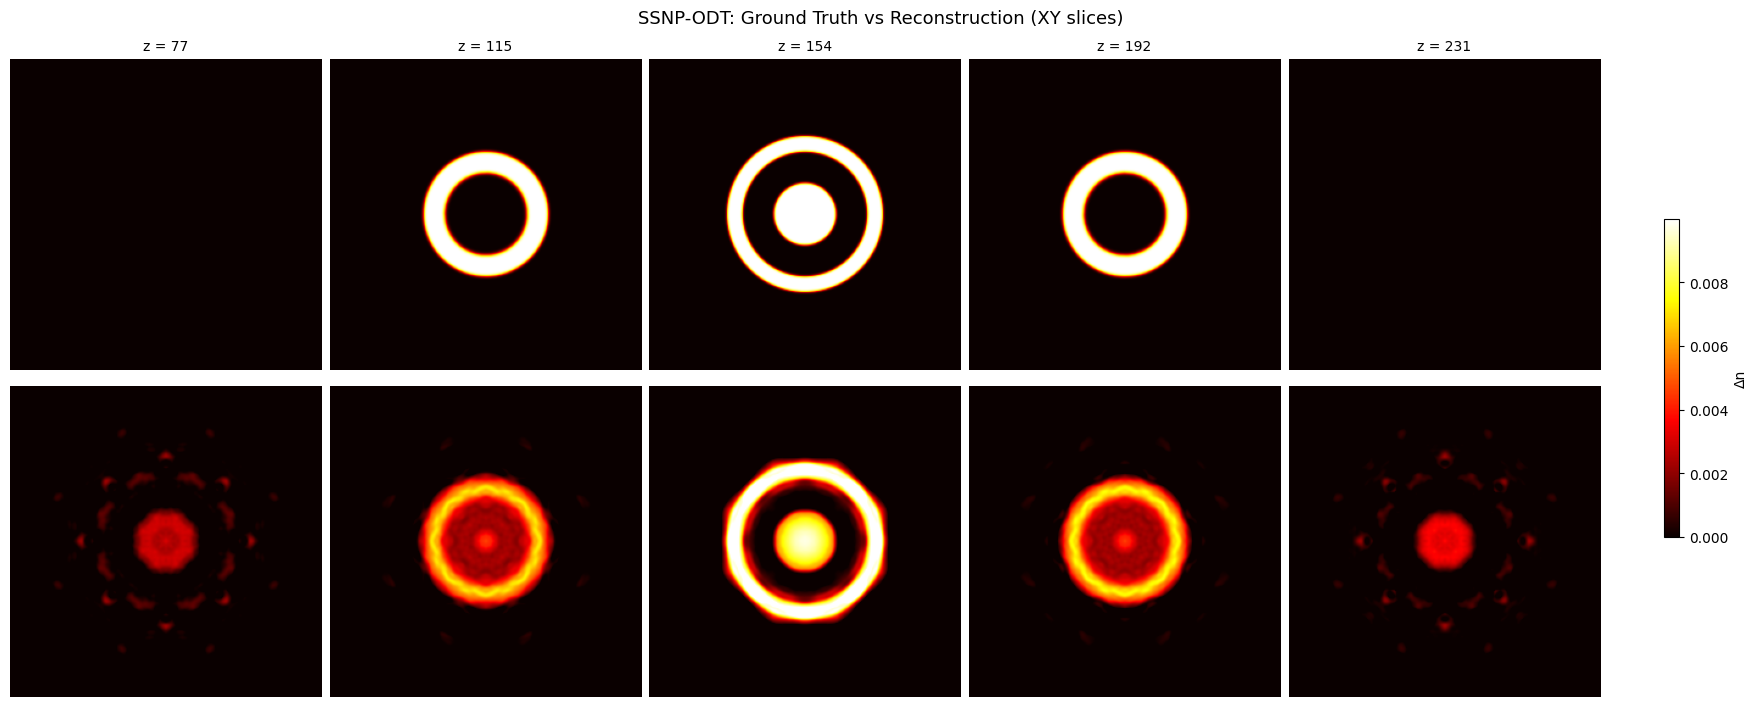

In [8]:
# Five XY slices: ground truth (top) vs reconstruction (bottom)
vmax = max(np.percentile(phantom_dn, 99.5), np.percentile(dn_recon, 99.5))

fig, axes = plt.subplots(2, 5, figsize=(17.5, 7), constrained_layout=True)

for col, zi in enumerate(z_indices):
    im = axes[0, col].imshow(phantom_dn[zi], cmap="hot", origin="lower", vmin=0, vmax=vmax)
    axes[0, col].set_title(f"z = {zi}", fontsize=10)
    axes[0, col].axis("off")

    axes[1, col].imshow(dn_recon[zi], cmap="hot", origin="lower", vmin=0, vmax=vmax)
    axes[1, col].axis("off")

axes[0, 0].set_ylabel("Ground truth", fontsize=11)
axes[1, 0].set_ylabel("Reconstruction", fontsize=11)
fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.01, pad=0.04, label="Δn")
fig.suptitle("SSNP-ODT: Ground Truth vs Reconstruction (XY slices)", fontsize=13)
plt.show()

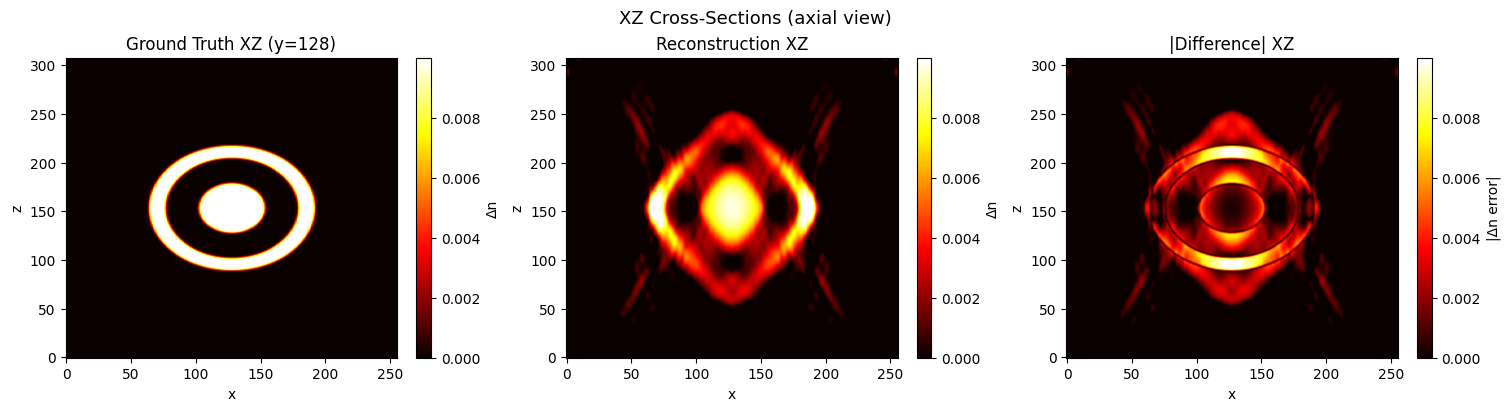

In [11]:
# XZ cross-sections with difference map
y_mid = ny // 2
gt_xz    = phantom_dn[:, y_mid, :]
recon_xz = dn_recon[:, y_mid, :]
diff_xz  = np.abs(gt_xz - recon_xz)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

im0 = axes[0].imshow(gt_xz, cmap="hot", origin="lower", vmin=0, vmax=vmax, aspect="auto")
axes[0].set_title(f"Ground Truth XZ (y={y_mid})")
axes[0].set_xlabel("x"); axes[0].set_ylabel("z")
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04, label="Δn")

im1 = axes[1].imshow(recon_xz, cmap="hot", origin="lower", vmin=0, vmax=vmax, aspect="auto")
axes[1].set_title("Reconstruction XZ")
axes[1].set_xlabel("x"); axes[1].set_ylabel("z")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04, label="Δn")

im2 = axes[2].imshow(diff_xz, cmap="hot", origin="lower", aspect="auto")
axes[2].set_title("|Difference| XZ")
axes[2].set_xlabel("x"); axes[2].set_ylabel("z")
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04, label="|Δn error|")

fig.suptitle("XZ Cross-Sections (axial view)", fontsize=13)
plt.show()

## 4. Quantitative Metrics

**NCC** (normalised cross-correlation, cosine similarity):
$$\text{NCC} = \frac{\hat{x} \cdot x_\text{ref}}{\|\hat{x}\|\,\|x_\text{ref}\|}$$

**NRMSE** (normalised root-mean-square error):
$$\text{NRMSE} = \frac{\sqrt{\frac{1}{N}\sum_i (\hat{x}_i - x_{\text{ref},i})^2}}{\max(x_\text{ref}) - \min(x_\text{ref})}$$

where $\hat{x}$ is the reconstruction and $x_\text{ref}$ is the ground truth, both flattened to 1D.

In [12]:
from src.visualization import compute_metrics

metrics = compute_metrics(dn_recon, phantom_dn)

with open("evaluation/metrics.json") as f:
    eval_cfg = json.load(f)

print(f"{'Metric':<10} {'Value':>10}   {'Boundary':>10}   {'Status':>6}")
print("-" * 45)
ncc_ok   = metrics['ncc']   >= eval_cfg['ncc_boundary']
nrmse_ok = metrics['nrmse'] <= eval_cfg['nrmse_boundary']
print(f"{'NCC':<10} {metrics['ncc']:>10.4f}   {eval_cfg['ncc_boundary']:>10.4f}   {'PASS' if ncc_ok else 'FAIL':>6}")
print(f"{'NRMSE':<10} {metrics['nrmse']:>10.4f}   {eval_cfg['nrmse_boundary']:>10.4f}   {'PASS' if nrmse_ok else 'FAIL':>6}")
print(f"{'SSIM':<10} {metrics['ssim']:>10.4f}   {'(info only)':>10}")

ModuleNotFoundError: No module named 'skimage'

In [ ]:
# Per-slice NCC to see axial variation in reconstruction quality
gt_flat  = phantom_dn.reshape(nz, -1)
rec_flat = dn_recon.reshape(nz, -1)

ncc_per_slice = np.array([
    np.dot(gt_flat[z], rec_flat[z]) /
    (np.linalg.norm(gt_flat[z]) * np.linalg.norm(rec_flat[z]) + 1e-12)
    for z in range(nz)
])

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(ncc_per_slice, color="steelblue", lw=1.5)
ax.axhline(metrics['ncc'], color="tomato", ls="--", lw=1.2, label=f"Overall NCC = {metrics['ncc']:.3f}")
ax.axhline(eval_cfg['ncc_boundary'], color="orange", ls=":", lw=1.2,
           label=f"Boundary = {eval_cfg['ncc_boundary']:.3f}")
ax.set_xlabel("z slice", fontsize=12)
ax.set_ylabel("NCC per slice", fontsize=12)
ax.set_title("Reconstruction Quality vs Axial Position", fontsize=13)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Running the Full Pipeline from Scratch

The cells below reproduce the data generation and reconstruction on a GPU. They are commented out to keep the notebook fast.

In [ ]:
# ── Step 1: Generate complex ODT measurements ──────────────────────────────
# Requires: data/sample.tiff  (phantom TIFF, included in repo)
# Output  : data/raw_data.npz (complex128, shape 1×8×256×256)
#           data/ground_truth.npz (float32, shape 1×308×256×256)

# import torch
# from src.generate_data import generate_measurements
#
# device = "cuda" if torch.cuda.is_available() else "cpu"
# measurements, phantom_dn, metadata = generate_measurements(data_dir="data", device=device)
# np.savez("data/raw_data.npz", measurements=measurements[np.newaxis])
# np.savez("data/ground_truth.npz", delta_n=phantom_dn[np.newaxis].astype(np.float32))
# print("Generated:", measurements.shape, measurements.dtype)

In [ ]:
# ── Step 2: Reconstruct 3D RI from complex field measurements ──────────────
# ~3 min on GH200 120GB GPU, ~hours on CPU
#
# import torch
# from src.physics_model import SSNPConfig, SSNPForwardModel
# from src.solvers import SSNPReconstructor
#
# device = "cuda" if torch.cuda.is_available() else "cpu"
#
# with open("data/meta_data.json") as f:
#     metadata = json.load(f)
# raw = np.load("data/raw_data.npz")
# gt  = np.load("data/ground_truth.npz")
# meas_np    = raw["measurements"][0].astype(np.complex128)
# phantom_dn = gt["delta_n"][0].astype(np.float64)
#
# config = SSNPConfig.from_metadata(metadata)
# model  = SSNPForwardModel(config, device=device)
#
# reconstructor = SSNPReconstructor(
#     n_iter=100, lr=5.0, tv_weight=0.0, positivity=True, device=device
# )
# meas_tensor = torch.tensor(meas_np, dtype=torch.complex128, device=device)
# dn_recon, loss_history = reconstructor.reconstruct(meas_tensor, model)
#
# # Save outputs
# import os
# os.makedirs("evaluation/reference_outputs", exist_ok=True)
# np.save("evaluation/reference_outputs/reconstruction.npy", dn_recon)
# np.save("evaluation/reference_outputs/loss_history.npy", np.array(loss_history))
# print(f"Final loss: {loss_history[-1]:.6f}")

## Summary

| | IDT | **ODT (this task)** |
|--|--|--|
| Measurement | Intensity $|E|^2$ | Complex field $E$ |
| Loss | $\|\,|E_\text{pred}| - \sqrt{I_\text{meas}}\|^2$ | $\|E_\text{pred} - E_\text{meas}\|^2$ |
| Information | Amplitude only | Amplitude **+ phase** |
| Learning rate | 50 | **5** (10× smaller; complex MSE gradients are larger) |
| NCC (baseline) | 0.809 | **0.877** |
| NRMSE (baseline) | 0.104 | **0.081** |

Access to the full complex field improves reconstruction quality (NCC 0.81→0.88, NRMSE 0.10→0.08) because the phase channel constrains axial position of scatterers independently of their amplitude — information that is completely lost in IDT.